In [2]:
import pandas as pd

df = pd.read_csv('boosted_posts_anonymized.csv')
print(df.shape)
df.head()

(9, 21)


,campaign_id,Reporting starts,Reporting ends,Campaign name,Campaign delivery,Attribution setting,Results,Result indicator,Cost per results,Ad set budget,...,Amount spent (EGP),Impressions,Reach,Ends,New messaging contacts,Cost per new messaging contact (EGP),Messaging conversations started,Cost per messaging conversation started (EGP),Results (initial),Results (initial) indicator
0,c1,2023-09-09,2026-10-09,Post A,archived,-,2329,actions:post_engagement,0.057149,140,...,133.10,2457,1531,2026-05-03,NaN,NaN,NaN,NaN,NaN,NaN
1,c2,2023-09-09,2026-10-09,Post B,archived,7-day click or 1-day view,315,actions:post_engagement,0.284635,120,...,89.66,1595,1145,2026-05-03,2.0,44.830000,2.0,44.830000,NaN,NaN
2,c3,2023-09-09,2026-10-09,Post A,completed,7-day click or 1-day view,15,actions:onsite_conversion.messaging_conversati...,6.578000,100,...,98.67,2154,1464,2026-05-04,14.0,7.047857,15.0,6.578000,NaN,NaN
3,c4,2023-09-09,2026-10-09,Post B,archived,7-day click or 1-day view,480,actions:post_engagement,0.244083,100,...,117.16,2519,1920,2026-05-12,10.0,11.716000,10.0,11.716000,NaN,NaN
4,c5,2023-09-09,2026-10-09,Post B,completed,7-day click or 1-day view,6,actions:onsite_conversion.messaging_conversati...,34.906667,120,...,209.44,3881,2689,2026-05-14,6.0,34.906667,6.0,34.906667,NaN,NaN


In [4]:
df['type'] = df['Result indicator'].apply(lambda x: 'messages' if 'messaging' in x else 'engagement')
print(df['type'].value_counts())

type
messages      6
engagement    3
Name: count, dtype: int64


In [6]:
msgs = df[df['type'] == 'messages'].copy()
msgs = msgs[['campaign_id', 'Campaign name', 'Amount spent (EGP)', 'Impressions', 'Results']]
msgs

,campaign_id,Campaign name,Amount spent (EGP),Impressions,Results
2,c3,Post A,98.67,2154,15
4,c5,Post B,209.44,3881,6
5,c6,Post C,206.68,5006,12
6,c7,Post D,197.84,3242,6
7,c8,Post E,479.52,5681,31
8,c9,Post F,477.86,6409,32


In [8]:
msgs['cost_per_conv'] = msgs['Amount spent (EGP)'] / msgs['Results']
msgs

,campaign_id,Campaign name,Amount spent (EGP),Impressions,Results,cost_per_conv
2,c3,Post A,98.67,2154,15,6.578000
4,c5,Post B,209.44,3881,6,34.906667
5,c6,Post C,206.68,5006,12,17.223333
6,c7,Post D,197.84,3242,6,32.973333
7,c8,Post E,479.52,5681,31,15.468387
8,c9,Post F,477.86,6409,32,14.933125


In [9]:
msgs.sort_values('cost_per_conv')

,campaign_id,Campaign name,Amount spent (EGP),Impressions,Results,cost_per_conv
2,c3,Post A,98.67,2154,15,6.578000
8,c9,Post F,477.86,6409,32,14.933125
7,c8,Post E,479.52,5681,31,15.468387
5,c6,Post C,206.68,5006,12,17.223333
6,c7,Post D,197.84,3242,6,32.973333
4,c5,Post B,209.44,3881,6,34.906667


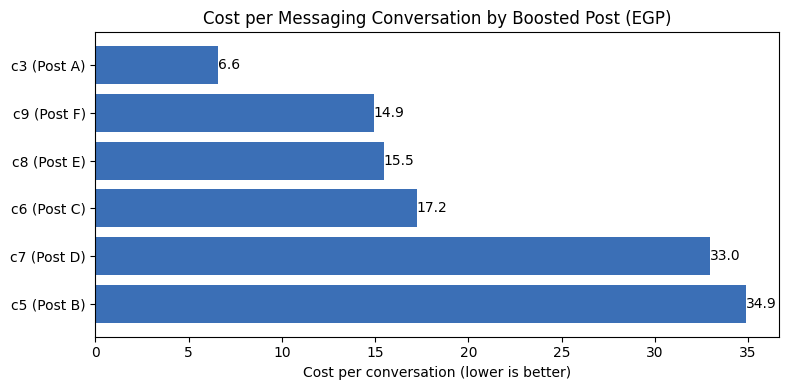

In [10]:
import matplotlib.pyplot as plt

msgs = msgs.sort_values('cost_per_conv')
labels = msgs['campaign_id'] + ' (' + msgs['Campaign name'] + ')'

plt.figure(figsize=(8, 4))
bars = plt.barh(labels, msgs['cost_per_conv'], color='#3b6fb6')
plt.bar_label(bars, fmt='%.1f')
plt.gca().invert_yaxis()
plt.title('Cost per Messaging Conversation by Boosted Post (EGP)')
plt.xlabel('Cost per conversation (lower is better)')
plt.tight_layout()
plt.savefig('cost_per_conversation.png', dpi=150)
plt.show()

In [11]:
msgs['spend_share'] = msgs['Amount spent (EGP)'] / msgs['Amount spent (EGP)'].sum() * 100
msgs['results_share'] = msgs['Results'] / msgs['Results'].sum() * 100
msgs[['campaign_id', 'spend_share', 'results_share']].round(1)

,campaign_id,spend_share,results_share
2,c3,5.9,14.7
8,c9,28.6,31.4
7,c8,28.7,30.4
5,c6,12.4,11.8
6,c7,11.8,5.9
4,c5,12.5,5.9
